# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** 25.10.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**Сведения о сдаче.**

Устройство: NVIDIA RTX 3060 12 GB, CUDA. PyTorch установлен отдельно с поддержкой CUDA (версия указана в выводе ячейки проверки окружения).

Режим: `FAST_MODE=False`. Выбранная ветка: `ATTACK_TRACK='transfer'` (5.3). Выполнены бонусы 7.1-7.5.

Источники: статьи, указанные непосредственно в соответствующих заданиях; для дополнительных экспериментов - [SCALE](https://arxiv.org/abs/2506.16659), [официальный код SCALE](https://github.com/OptimAI-Lab/Minimalist_LLM_Pretraining) и [BAOC](https://arxiv.org/abs/2605.04711). Дополнительные реализации LLMSCALE и CNNScale адаптированы для экспериментов и не являются буквальной копией авторского кода.

Нерешённых обязательных задач нет. Из двух альтернатив выбрана 5.3; задание 5.2 не выполнялось.


In [1]:
!nvidia-smi

Sun Oct 25 15:52:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.88                 KMD Version: 610.88        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3060      WDDM  |   00000000:01:00.0  On |                  N/A |
| 30%   43C    P8             18W /  170W |    1044MiB /  12288MiB |      8%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Т.к. у меня стоит 3060 на 12 гб - локально поставил следующую версию pytorch, отличную от requirements.txt: https://download.pytorch.org/whl/cu130

In [2]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
from itertools import chain
import json
import math
from pathlib import Path
import time
import timeit
import gc


import numpy as np
import matplotlib.pyplot as plt




import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets


plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.14.1+cu130
CUDA available:  True
MPS available:   False


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='cuda')

In [4]:
FAST_MODE =  False   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'transfer'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = {'7.1', '7.2', '7.3', '7.4', '7.5'}   # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}
RUN_LLM_EXPERIMENT = True  # Дополнительный эксперимент (не был обязателен для выполнения лабораторной)


Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [5]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [6]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [7]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    # x: (B, C_in, H, W), weight: (C_out, C_in / groups, kh, kw) -> (B, C_out, H_out, W_out)
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape

    cols = F.unfold(
        x,
        kernel_size=(kh, kw),
        dilation=dilation,
        padding=padding,
        stride=stride
    )

    cols = cols.reshape(B, groups, C_in // groups * kh * kw, -1)
    w = weight.reshape(groups, C_out // groups, -1)

    out = torch.matmul(w.unsqueeze(0), cols)

    out = out.reshape(
        B,
        C_out,
        *conv_output_shape((H, W), (kh, kw), stride, padding, dilation)
    )

    if bias is not None:
        out = out + bias.reshape(1, -1, 1, 1)

    return out

In [8]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [9]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


**Ответ:**

При использовании unfold каждое локальное окно изображения разворачивается в отдельный столбец матрицы. Т.к. соседние окна перекрываются, одни и те же элементы входного изображения дублируются.

Для квадратного ядра размером k * k при шаге 1 и сохранении пространственных размеров выхода число элементов промежуточной матрицы оказывается в k ** 2 раз больше числа элементов исходного изображения. Например, для ядра 3 * 3 оно увеличивается в 9 раз, а для ядра 5 × 5 - в 25 раз.

То есть использование unfold может значительно увеличивать расход памяти, особенно в случае больших ядер.


FFT-свёртка использует преобразование Фурье, которое позволяет перейти от пространственного представления изображения к частотному. В силу свойств преобразований Фурье свёртка в пространственной бласти сводится к поэлементному умножению в частотной области.

Это позволяет избежать повторяющихся операций при перемещении ядра по изображению. Этот подход может хорошо работать на больших ядрах свёртки, но требует дополнительных вычислений на прямое и обратное преобразования Фурье, поэтому для небольших ядер FFT не всегда может давать прирост эффективности.


## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [10]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding

        kh, kw = weight.shape[-2:]
        H, W = x.shape[-2:]
        H_out, W_out = grad_out.shape[-2:]

        output_padding = (
            H - ((H_out - 1) * s - 2 * p + kh),
            W - ((W_out - 1) * s - 2 * p + kw)
        )

        grad_x = F.conv_transpose2d(
            grad_out,
            weight,
            stride=s,
            padding=p,
            output_padding=output_padding
        )

        cols = F.unfold(
            x,
            kernel_size=(kh, kw),
            stride=s,
            padding=p
        )

        grad_w = torch.einsum(
            'bol,bcl->oc',
            grad_out.flatten(2),
            cols
        ).reshape_as(weight)

        grad_b = (
            grad_out.sum(dim=(0, 2, 3))
            if ctx.needs_input_grad[2]
            else None
        )

        return grad_x, grad_w, grad_b, None, None

In [11]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

**Ответ:**

Для свёртки с ядром 3 * 3, stride 2 и padding 1 рассмотрим два размера входа: H = 7 и H = 8. Для них высота выхода равна 4.

Транспонированная свёртка не может однозначно восстановить исходный размер только по размеру выхода.

Поэтому для H = 7 требуется output_padding = 0, а для H = 8 - output_padding = 1.

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [12]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [13]:
def empirical_rf(model, in_channels=1, size=96):
    # -> (высота, ширина) bounding box пикселей входа, влияющих на центральный выход
    x = torch.randn(1, in_channels, size, size, requires_grad=True)

    y = model(x)
    center = y[0, :, y.shape[-2] // 2, y.shape[-1] // 2].sum()

    grad = torch.autograd.grad(center, x)[0]

    mask = grad[0].abs().sum(dim=0) > 0
    rows, cols = torch.where(mask)

    return (
        rows.max().item() - rows.min().item() + 1,
        cols.max().item() - cols.min().item() + 1
    )

In [14]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

**Ответ:**

Усредняющие ядра без нелинейностей позволяют проверить теоретическое рецептивное поле, поскольку все элементы ядра положительны и градиенты распространяются по всем доступным путям без обнуления.

При использовании MaxPool градиент передаётся только через элементы, выбранные максимумами в окнах. Из-за этого карта градиентов становится более разреженной, а фактическая область влияния может уменьшиться. При этом размер bounding box не обязательно должен измениться, т.к. ненулевые градиенты всё ещё могут достигать его крайних пикселей.

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [15]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    accumulated = torch.zeros(size, size)

    for _ in range(n_inputs):
        x = torch.randn(1, in_channels, size, size, requires_grad=True)

        y = model(x)
        center = y[0, :, y.shape[-2] // 2, y.shape[-1] // 2].sum()

        grad = torch.autograd.grad(center, x)[0]

        accumulated += grad[0].abs().sum(dim=0).detach()

    rows = accumulated.sum(dim=1)
    probabilities = rows / rows.sum()

    positions = torch.arange(size, dtype=probabilities.dtype)
    mean = (positions * probabilities).sum()

    return (((positions - mean) ** 2 * probabilities).sum().sqrt()).item()

In [16]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [17]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.79   1.29   1.97   3.08   4.44


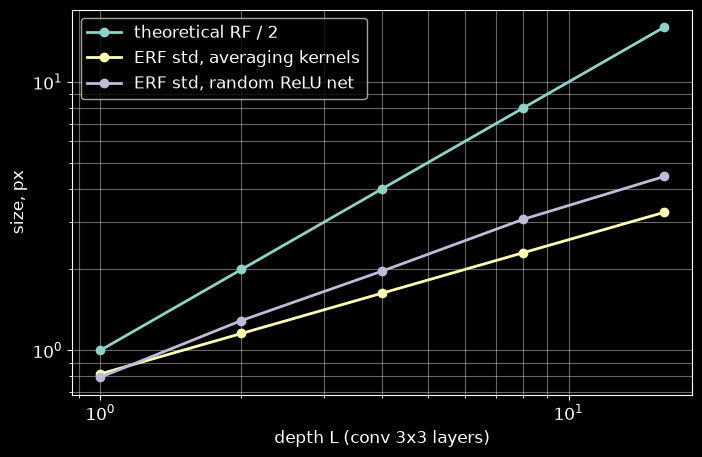

In [18]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

**Ответ:**

Теоретическое рецептивное поле увеличивается линейно с глубиной сети, поэтому наклон его графика в log-log масштабе близок к 1. Для усредняющих свёрток эффективное RF растёт пропорционально квадратному корню из глубины, что соответствует наклону 0,5.

То есть относительная ширина эффективного RF постепенно уменьшается. В случайной сети с ReLU распределение градиентов также зависит от активаций и весов. В тестовом эксперименте ERF такой сети увеличивалось быстрее, чем у усредняющей. Однако этот результат может зависеть от инициализации и архитектуры.

---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [19]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum

        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))

        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        if self.training:
            mean = x.mean(dim=(0, 2, 3), keepdim=True)
            var = x.var(dim=(0, 2, 3), unbiased=False, keepdim=True)

            n = x.shape[0] * x.shape[2] * x.shape[3]

            with torch.no_grad():
                self.running_mean.lerp_(mean.reshape(-1), self.momentum)
                self.running_var.lerp_(
                    var.reshape(-1) * n / (n - 1),
                    self.momentum
                )
                self.num_batches_tracked.add_(1)
        else:
            mean = self.running_mean.reshape(1, -1, 1, 1)
            var = self.running_var.reshape(1, -1, 1, 1)

        x_normalized = (x - mean) / torch.sqrt(var + self.eps)

        return (
            x_normalized * self.weight.reshape(1, -1, 1, 1)
            + self.bias.reshape(1, -1, 1, 1)
        )

In [20]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

**Ответ:**

Для нормализации текущего батча используется смещённая оценка дисперсии с делением на n, а для накопленных статистик - несмещённая с делением на n-1. Это позволяет корректировать систематическое занижение оценки дисперсии исходного распределения.

При B = 4 и размере карты 5*5 получаем n = 100. Несмещённая оценка отличается от смещённой в 100/99 раза, то есть примерно на 1%.

При B = 2 и размере карты 1*1 получаем n = 2, несмещённая оценка оказывается в 2 раза больше. В итоге на маленьких батчах различие между оценками становится существенным.

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

**Ответ:**

В режиме eval() BatchNorm использует фиксированные статистики:

$$
\operatorname{BN}(z)=
\gamma\frac{z-\hat\mu}{\sqrt{\hat\sigma^2+\varepsilon}}+\beta
$$

Свёртку можно записать как:

$$
z=Wx+b
$$

Подставляем свёртку в BatchNorm:

$$
y=\gamma\frac{Wx+b-\hat\mu}{\sqrt{\hat\sigma^2+\varepsilon}}+\beta
$$

Раскрываем скобки и группируем слагаемые:

$$
y=\underbrace{\frac{\gamma}{\sqrt{\hat\sigma^2+\varepsilon}}W}_{W'}x
+\underbrace{\frac{\gamma(b-\hat\mu)}{\sqrt{\hat\sigma^2+\varepsilon}}+\beta}_{b'}
$$

Получается новая свёртка с весами:

$$
\boxed{W'_o=W_o\frac{\gamma_o}{\sqrt{\hat\sigma_o^2+\varepsilon}}}
$$

$$
\boxed{b'_o=\beta_o+\frac{\gamma_o(b_o-\hat\mu_o)}{\sqrt{\hat\sigma_o^2+\varepsilon}}}
$$

In [21]:
@torch.no_grad()
def fuse_conv_bn(conv, bn):
    scale = bn.weight / torch.sqrt(bn.running_var + bn.eps)
    bias = conv.bias if conv.bias is not None else torch.zeros_like(bn.running_mean)

    fused = nn.Conv2d(
        conv.in_channels,
        conv.out_channels,
        conv.kernel_size,
        stride=conv.stride,
        padding=conv.padding,
        dilation=conv.dilation,
        groups=conv.groups,
        bias=True,
        padding_mode=conv.padding_mode,
        device=conv.weight.device,
        dtype=conv.weight.dtype
    )

    fused.weight.copy_(conv.weight * scale.reshape(-1, 1, 1, 1))
    fused.bias.copy_((bias - bn.running_mean) * scale + bn.bias)

    return fused.eval()


def fuse_sequential(seq):
    layers = []
    i = 0

    while i < len(seq):
        if (
            i + 1 < len(seq)
            and isinstance(seq[i], nn.Conv2d)
            and isinstance(seq[i + 1], nn.BatchNorm2d)
        ):
            layers.append(fuse_conv_bn(seq[i], seq[i + 1]))
            i += 2
        else:
            layers.append(copy.deepcopy(seq[i]))
            i += 1

    return nn.Sequential(*layers).eval()

In [22]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [23]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [24]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 51.6 ms   fused: 48.8 ms   speedup 1.06x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

**Ответ:**

Слияние корректно в режиме eval, т.к. в нём BatchNorm использует фиксированные накопленные статистики. За счёт этого нормализация становится аффинным преобразованием, которое можно включить непосредственно в веса и смещения свёртки.

В режиме train статистики зависят от текущего батча, поэтому заменить BatchNorm свёрткой с постоянными весами уже нельзя.

Слияние позволяет убрать отдельную операцию нормализации, сократить обращения к памяти и уменьшить накладные расходы.

Реальный выигрыш зависит от архитектуры, размеров тензоров, оборудования и используемых оптимизаций вычислений.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

**Ответ:**

Для ReLU с симметрично распределёнными входами второй момент активаций уменьшается вдвое, т.к. отрицательная часть распределения обнуляется. В силу этого для сохранения дисперсии необходимо выбрать дисперсию весов v = 2/n, что соответствует инициализации Kaiming.

Для tanh в линейном режиме функция приблизительно равна тождественному преобразованию, поэтому достаточно v = 1/n. При равной ширине слоёв это соответствует инициализации Xavier.

В стандартной инициализации PyTorch дисперсия весов равна 1/(3n). В результате, при использовании ReLU дисперсия сигнала уменьшается в 6 раз за слой, а стандартное отклонение умножается примерно на 0,408.

In [25]:
INITS = {
    'N(0, 0.01^2)':    lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier':          nn.init.xavier_normal_,
    'Kaiming':         lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)

    x = torch.randn(n, width)
    stds = []

    with torch.no_grad():
        for _ in range(depth):
            layer = nn.Linear(width, width, bias=False)
            init(layer.weight)

            x = act(layer(x))
            stds.append(x.std().item())

    return stds

In [26]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.882


np.float64(0.41000275082847326)

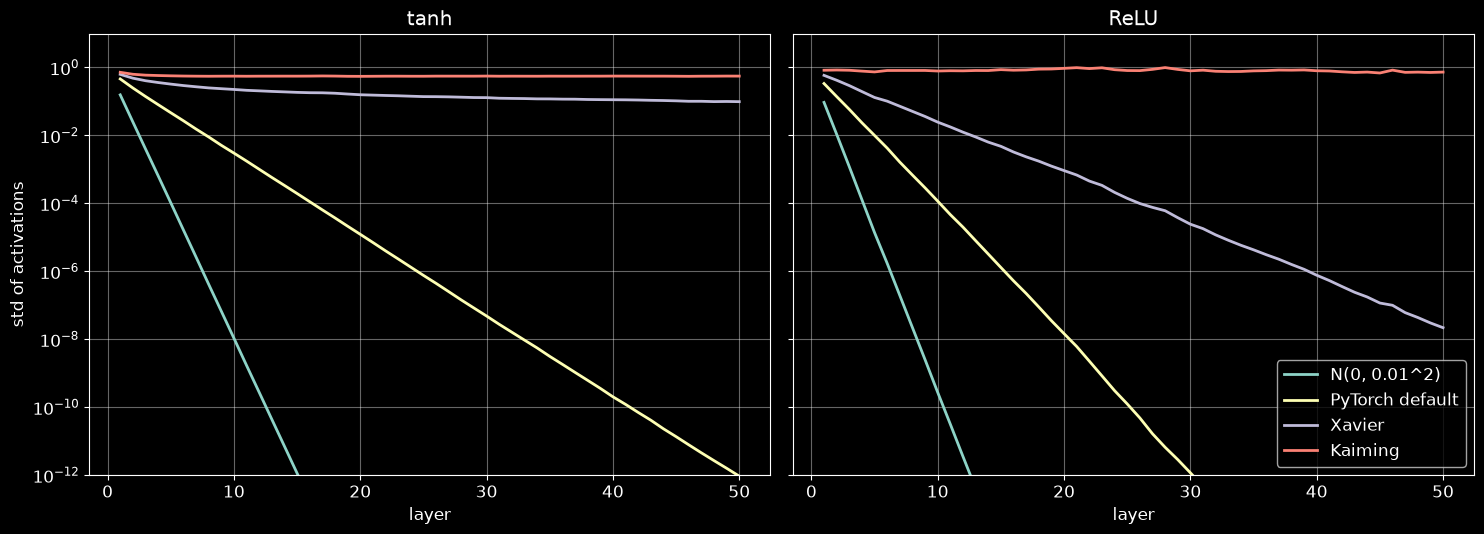

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

**Ответ:**

На 50 слоях наиболее стабильный масштаб активаций демонстрируют Kaiming + ReLU и Kaiming + tanh. Для первой комбинации отношение стандартного отклонения последнего слоя к первому составляет примерно 0.880, а для второй  -  0.770.

В случае ReLU это объясняется подбором дисперсии весов с учётом изменения второго момента активаций. В случае tanh насыщение функции способствует сохранению масштаба, при этом нет гарантий хорошего распространения градиентов.

Xavier + tanh показывает постепенное уменьшение стандартного отклонения, а PyTorch default с ReLU приводит к быстрому затуханию сигнала.

Современные сети вроде ResNet используют нормализацию и residual connections, которые помогают стабилизировать распространение активаций и градиентов. Для свёрточных слоёв таких моделей часто применяется Kaiming-инициализация, то есть результаты эксперимента с обычной MLP нельзя напрямую переносить на ResNet или другие архитектуры.

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [28]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            lr, eps, wd = group['lr'], group['eps'], group['weight_decay']

            for p in group['params']:
                if p.grad is None:
                    continue

                grad = p.grad
                state = self.state[p]

                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)

                state['step'] += 1
                step = state['step']

                p.mul_(1 - lr * wd)

                state['exp_avg'].mul_(beta1).add_(grad, alpha=1 - beta1)
                state['exp_avg_sq'].mul_(beta2).addcmul_(grad, grad, value=1 - beta2)

                if group['bias_correction']:
                    denom = state['exp_avg_sq'].sqrt().div_(math.sqrt(1 - beta2 ** step)).add_(eps)
                    p.addcdiv_(state['exp_avg'], denom, value=-lr / (1 - beta1 ** step))
                else:
                    denom = state['exp_avg_sq'].sqrt().add_(eps)
                    p.addcdiv_(state['exp_avg'], denom, value=-lr)

In [29]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [30]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


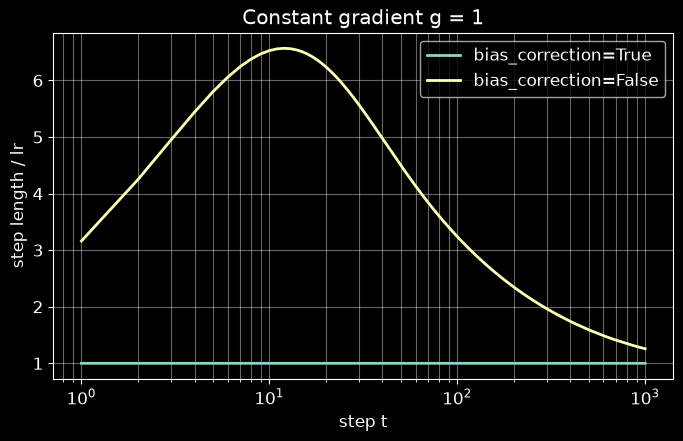

In [31]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

**Ответ:**

При постоянном градиенте $g=1$ скользящие моменты Adam равны $m(t)=1-\beta_1^t$ и $v(t)=1-\beta_2^t$.

Без bias correction длина шага равна

$$
\frac{\eta(1-\beta_1^t)}{\sqrt{1-\beta_2^t}+\varepsilon}.
$$

При $\beta_1=0.9$ и $\beta_2=0.999$ первый шаг составляет примерно $3.16\eta$, а максимальная длина шага достигает примерно $6.57\eta$.

Это происходит из-за различной скорости накопления первого и второго моментов, которые изначально равны нулю. В результате в начале обучения обновления могут оказаться значительно больше заданного learning rate и привести к нестабильности.

Bias correction устраняет это начальное смещение моментов. При постоянном единичном градиенте длина шага после коррекции примерно равна $\eta$.

Так как речь зашла об оптимизаторах, я решил вспомнить, что в прошлом году в рамках лабораторной работы обучал простые нейросети с помощью оптимизатора SCALE из статьи (2025):
https://arxiv.org/abs/2506.16659

Авторы также опубликовали конференционную версию на ICML (2026):
https://proceedings.mlr.press/v306/glentis26a.html

Реализация на GitHub:
https://github.com/OptimAI-Lab/Minimalist_LLM_Pretraining

Для отдельного эксперимента с LLM дополнительно нужны библиотеки:
`uv pip install "transformers>=4.45,<5" "datasets>=3,<5"`

Оптимизатор предложен прежде всего для претрейна LLM.

Основная идея примерно следующая: взять SGD, добавить нормализацию градиентов по столбцам матриц и хранить momentum только для последнего слоя языковой модели. Для одномерных параметров при этом сохраняются адаптивные обновления.

В экспериментах авторов последний слой `lm_head` у исследованных LLM характеризуется особенно высокой дисперсией стохастических градиентов. Momentum уменьшает разброс обновлений за счёт усреднения градиентов и помогает сходимости без дополнительных состояний у большинства остальных матриц.

Было бы интересно проверить масштабирование алгоритма на LLM больше 7B параметров и попробовать динамически выбирать слои, для которых хранится momentum, при заданном бюджете памяти. Нужно ещё проверить, насколько полезность momentum действительно меняется между слоями и в ходе обучения.

Близкая работа о распределении конфигураций оптимизаторов при ограничении памяти:
https://arxiv.org/abs/2605.04711
Её основная схема не требует регулярного перераспределения состояний в ходе обучения.

Ниже представлена упрощённая экспериментальная реализация SCALE, адаптированная под модель и тренировочный цикл. Это не буквальная копия авторского кода.


In [32]:
class LLMSCALE(torch.optim.Optimizer):
    def __init__(self, model, lr=1e-5, beta=0.9, eps=1e-8, weight_decay=0.0):
        super().__init__(
            model.parameters(),
            dict(lr=lr, beta=beta, eps=eps, weight_decay=weight_decay)
        )
        self.head_id = id(model.get_output_embeddings().weight)
        self.embed_id = id(model.get_input_embeddings().weight)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()

        for group in self.param_groups:
            lr, beta, eps, wd = (
                group[k] for k in ('lr', 'beta', 'eps', 'weight_decay')
            )

            for p in group['params']:
                if p.grad is None:
                    continue

                g, state = p.grad, self.state[p]

                if p.ndim < 2:
                    if 'm' not in state:
                        state.update(
                            t=0,
                            m=torch.zeros_like(p),
                            v=torch.zeros_like(p)
                        )

                    state['t'] += 1
                    state['m'].lerp_(g, 1 - beta)
                    state['v'].mul_(0.999).addcmul_(g, g, value=0.001)

                    m = state['m'] / (1 - beta ** state['t'])
                    v = state['v'] / (1 - 0.999 ** state['t'])
                    update = m / (v.sqrt() + eps)
                else:
                    if id(p) == self.head_id:
                        if 'm' not in state:
                            state['m'] = torch.zeros_like(p)
                        state['m'].lerp_(g, 1 - beta)
                        g = state['m']

                    flat = g.reshape(g.shape[0], -1)
                    dim = 0 if id(p) == self.embed_id else 1
                    norm = flat.square().mean(
                        dim=dim, keepdim=True
                    ).sqrt().clamp_min(eps)

                    update = (flat / norm).reshape_as(p)

                p.mul_(1 - lr * wd).add_(update, alpha=-lr)

        return loss

In [33]:
if RUN_LLM_EXPERIMENT:
    from datasets import load_dataset
    from transformers import AutoTokenizer, LlamaConfig, LlamaForCausalLM
    MODEL_ID = 'roneneldan/TinyStories-8M'
    DATASET_ID = 'roneneldan/TinyStories'

    STEPS = 2000
    SEQ_LEN = 256
    BATCH = 1
    ACCUM = 8
    WARMUP = 200
    EVAL_EVERY = 250

    TRAIN_N = 40000
    VAL_N = 512

    assert torch.cuda.is_available()

    amp_dtype = (
        torch.bfloat16 if torch.cuda.is_bf16_supported()
        else torch.float16
    )

    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    cache = Path(f'tinystories_pretrain_{TRAIN_N}_{VAL_N}.json')

    if cache.exists():
        texts = json.loads(cache.read_text(encoding='utf-8'))
    else:
        train_ds = load_dataset(
            DATASET_ID, split='train', streaming=True
        ).shuffle(seed=42, buffer_size=2048)

        val_ds = load_dataset(
            DATASET_ID, split='validation', streaming=True
        )

        texts = {
            'train': [x['text'] for x in train_ds.take(TRAIN_N)],
            'val': [x['text'] for x in val_ds.take(VAL_N)]
        }

        cache.write_text(
            json.dumps(texts, ensure_ascii=False),
            encoding='utf-8'
        )

    def pack(texts):
        encoded = tokenizer(texts, add_special_tokens=False)['input_ids']
        flat = torch.tensor(
            list(chain.from_iterable(
                ids + [tokenizer.eos_token_id] for ids in encoded
            )),
            dtype=torch.long
        )
        n = flat.numel() // SEQ_LEN
        return flat[:n * SEQ_LEN].reshape(n, SEQ_LEN).pin_memory()

    train_blocks = pack(texts['train'])
    val_blocks = pack(texts['val'])[:128]

    needed = STEPS * ACCUM * BATCH
    generator = torch.Generator().manual_seed(42)

    indices = []
    while needed > 0:
        permutation = torch.randperm(len(train_blocks), generator=generator)
        selected = permutation[:needed]
        indices.append(selected)
        needed -= len(selected)

    order = torch.cat(indices).reshape(STEPS, ACCUM, BATCH)

    print(f'Train blocks: {len(train_blocks)}')
    print(f'Validation blocks: {len(val_blocks)}')
    print(f'Train tokens: {STEPS * BATCH * ACCUM * SEQ_LEN:,}')

    config = LlamaConfig(
        vocab_size=len(tokenizer),
        hidden_size=640,
        intermediate_size=1792,
        num_hidden_layers=16,
        num_attention_heads=10,
        num_key_value_heads=10,
        max_position_embeddings=SEQ_LEN,
        hidden_act='silu',
        attention_dropout=0.0,
        tie_word_embeddings=False,
        use_cache=False,
        bos_token_id=tokenizer.bos_token_id,
        eos_token_id=tokenizer.eos_token_id
    )

    torch.manual_seed(123)
    probe = LlamaForCausalLM(config)

    print(f'Parameters: {sum(p.numel() for p in probe.parameters()) / 1e6:.2f}M')
    print(f'Train blocks: {len(train_blocks)}')
    print(f'Validation blocks: {len(val_blocks)}')

    del probe




D:\Deep-Learning-homeworks\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Train blocks: 35463
Validation blocks: 128
Train tokens: 4,096,000
Parameters: 145.61M
Train blocks: 35463
Validation blocks: 128


In [34]:
if RUN_LLM_EXPERIMENT:
    def lr_multiplier(step, steps, warmup):
        if step < warmup:
            return (step + 1) / warmup

        progress = min(1.0, (step - warmup) / (steps - warmup))
        return 0.1 + 0.9 * (1 + math.cos(math.pi * progress)) / 2


    @torch.no_grad()
    def evaluate_pretrain(model):
        model.eval()
        total, count = 0.0, 0

        for batch in val_blocks.split(8):
            batch = batch.to(device)

            with torch.autocast('cuda', dtype=amp_dtype):
                loss = model(input_ids=batch, labels=batch).loss

            tokens = batch.size(0) * (batch.size(1) - 1)
            total += loss.item() * tokens
            count += tokens

        model.train()
        return total / count


    def pretrain_run(name, lr, steps=STEPS, warmup=WARMUP, eval_every=EVAL_EVERY):
        torch.manual_seed(123)
        torch.cuda.manual_seed_all(123)

        model = LlamaForCausalLM(config).to(device)
        model.gradient_checkpointing_enable()
        model.train()

        assert (
            model.get_input_embeddings().weight.data_ptr()
            != model.get_output_embeddings().weight.data_ptr()
        )

        if name == 'AdamW':
            opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0)
        elif name == 'MyAdamW':
            opt = MyAdamW(model.parameters(), lr=lr, weight_decay=0)
        else:
            opt = LLMSCALE(model, lr=lr, weight_decay=0)

        scheduler = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda t: lr_multiplier(t, steps, warmup)
        )
        scaler = torch.amp.GradScaler(
            'cuda', enabled=amp_dtype == torch.float16
        )

        history = {'train': [], 'steps': [0], 'val': [evaluate_pretrain(model)]}

        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
        start = time.perf_counter()

        for step in range(steps):
            opt.zero_grad(set_to_none=True)
            train_loss = 0.0

            for micro in range(ACCUM):
                batch = train_blocks[order[step, micro]].to(device)

                with torch.autocast('cuda', dtype=amp_dtype):
                    loss = model(input_ids=batch, labels=batch).loss

                scaler.scale(loss / ACCUM).backward()
                train_loss += loss.item() / ACCUM

            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

            scaler.step(opt)
            scaler.update()
            scheduler.step()

            history['train'].append(train_loss)

            if (step + 1) % eval_every == 0:
                val_loss = evaluate_pretrain(model)
                history['steps'].append(step + 1)
                history['val'].append(val_loss)
                print(name, step + 1, round(train_loss, 3),
                      round(math.exp(val_loss), 2))

        torch.cuda.synchronize()
        history['time'] = time.perf_counter() - start
        history['peak_gb'] = torch.cuda.max_memory_allocated() / 2**30
        history['state_mb'] = sum(
            v.numel() * v.element_size()
            for state in opt.state.values()
            for v in state.values()
            if torch.is_tensor(v)
        ) / 2**20

        del model, opt, scheduler, scaler
        gc.collect()
        torch.cuda.empty_cache()

        return history



    COMMON_LR = 3e-4

    pretrain_histories = {}

    for name in ('AdamW', 'MyAdamW', 'SCALE'):
        pretrain_histories[name] = pretrain_run(
            name,
            lr=COMMON_LR,
            steps=300,
            warmup=30,
            eval_every=50
        )

AdamW 50 5.884 366.98
AdamW 100 5.094 147.58
AdamW 150 4.575 72.29
AdamW 200 4.243 50.45
AdamW 250 4.118 42.82
AdamW 300 4.053 38.99
MyAdamW 50 5.884 366.93
MyAdamW 100 5.11 149.0
MyAdamW 150 4.593 73.5
MyAdamW 200 4.255 50.75
MyAdamW 250 4.127 43.17
MyAdamW 300 4.054 39.3
SCALE 50 5.532 241.18
SCALE 100 4.902 102.36
SCALE 150 4.385 58.97
SCALE 200 4.126 43.19
SCALE 250 4.005 37.08
SCALE 300 3.872 34.18


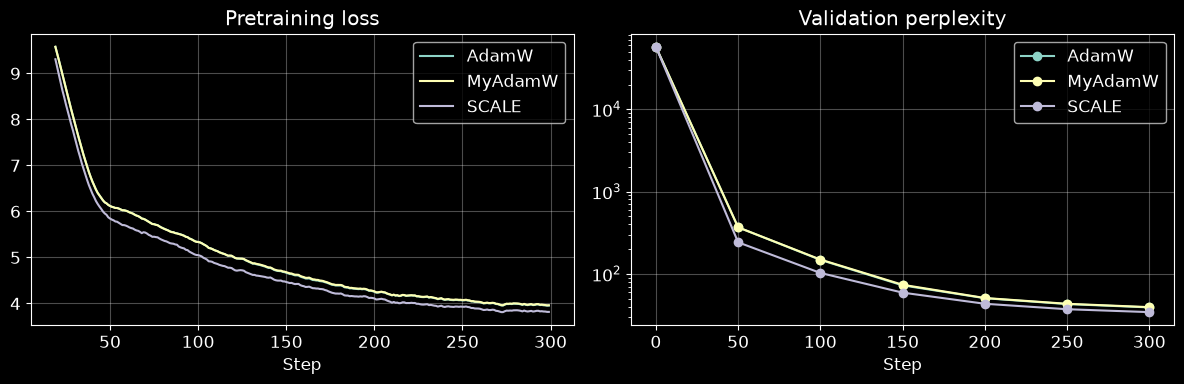

Optimizer           PPL     State MB    Peak GB       Time
AdamW             38.99       1111.0       3.40      412.2
MyAdamW           39.30       1111.0       3.39      394.4
SCALE             34.18        122.9       2.43      385.5


In [35]:
if RUN_LLM_EXPERIMENT:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for name, h in pretrain_histories.items():
        smooth = np.convolve(
            h['train'], np.ones(20) / 20, mode='valid'
        )

        axes[0].plot(
            np.arange(19, len(h['train'])),
            smooth,
            label=name
        )

        axes[1].plot(
            h['steps'],
            np.exp(h['val']),
            'o-',
            label=name
        )

    axes[0].set(title='Pretraining loss', xlabel='Step')
    axes[1].set(title='Validation perplexity', xlabel='Step')
    axes[1].set_yscale('log')

    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plt.show()

    print(f'{"Optimizer":<12} {"PPL":>10} {"State MB":>12} {"Peak GB":>10} {"Time":>10}')

    for name, h in pretrain_histories.items():
        print(
            f'{name:<12} {math.exp(h["val"][-1]):>10.2f} '
            f'{h["state_mb"]:>12.1f} '
            f'{h["peak_gb"]:>10.2f} '
            f'{h["time"]:>10.1f}'
        )

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [36]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    progress = min(1.0, step / total_steps)
    return min_ratio + (1 - min_ratio) * (
        1 + math.cos(math.pi * progress)
    ) / 2

In [37]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

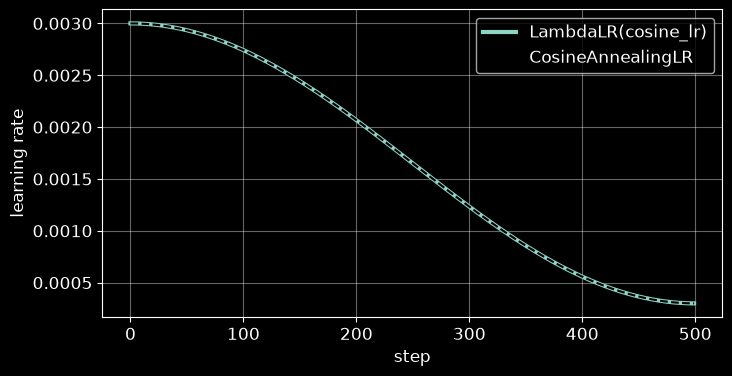

In [38]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

**Ответ:**

AdamW (и другие адаптивные оптимизаторы) учитывает статистики градиентов, но не устраняет стохастический шум, возникающий при обучении на мини-батчах.

При постоянном lr даже около минимума параметры продолжают колебаться из-за случайных градиентов. Уменьшение lr позволяет снизить влияние случайных колебаний, стабилизировать обучение и приблизиться к минимуму функции потерь

Cosine shedule реализует плавное уменьшение шага, сохраняет достаточно большой lr в начале обучения и снижает его к концу.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [39]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

D:\Deep-Learning-homeworks\.venv\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='cuda:0'),
 tensor([0.2470, 0.2435, 0.2616], device='cuda:0'))

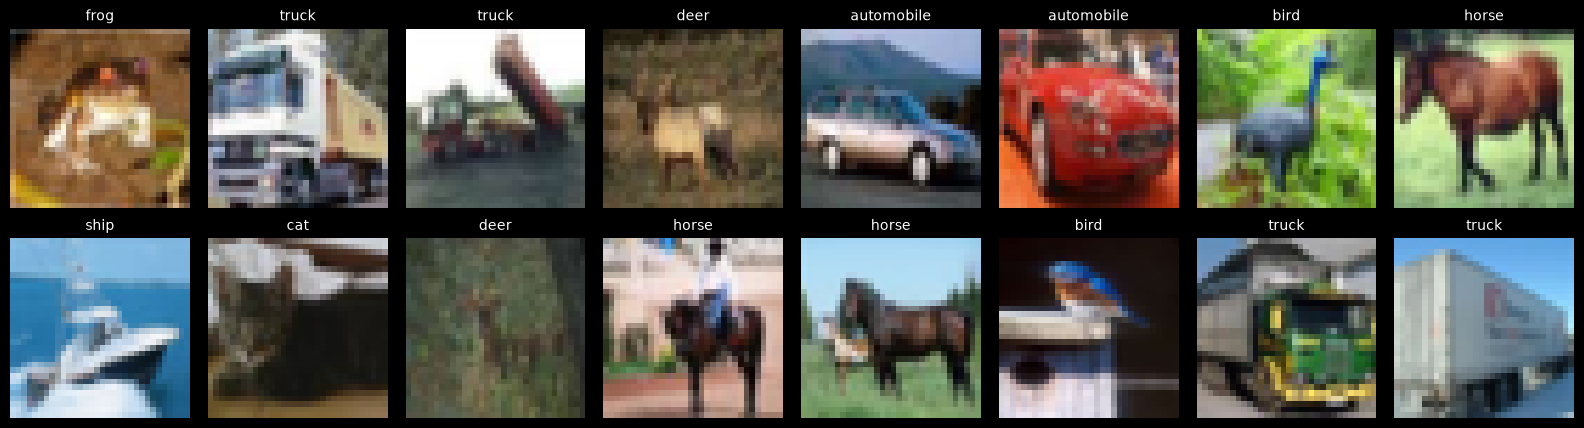

In [40]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [41]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if separable:
        return nn.Sequential(
            nn.Conv2d(c_in, c_in, 3, stride=stride, padding=1, groups=c_in, bias=False),
            nn.Conv2d(c_in, c_out, 1, bias=False)
        )

    return nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual

        self.conv1 = conv3x3(c_in, c_out, stride, separable)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = conv3x3(c_out, c_out, separable=separable)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.relu = nn.ReLU(inplace=True)

        if residual:
            self.shortcut = (
                nn.Identity() if stride == 1 and c_in == c_out else
                nn.Sequential(
                    nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False),
                    nn.BatchNorm2d(c_out)
                )
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))

        if self.residual:
            out = out + self.shortcut(x)

        return self.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0

        n = (depth - 2) // 6

        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]),
            nn.ReLU(inplace=True)
        )

        self.stages = nn.Sequential(
            self._make_stage(widths[0], widths[0], n, 1, residual, separable),
            self._make_stage(widths[0], widths[1], n, 2, residual, separable),
            self._make_stage(widths[1], widths[2], n, 2, residual, separable)
        )

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(widths[2], n_classes)

    @staticmethod
    def _make_stage(c_in, c_out, n, stride, residual, separable):
        return nn.Sequential(
            Block(c_in, c_out, stride, residual, separable),
            *(Block(c_out, c_out, 1, residual, separable) for _ in range(n - 1))
        )

    def forward(self, x):
        x = self.stages(self.stem(x))
        x = self.pool(x).flatten(1)
        return self.fc(x)

In [42]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [43]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()

    decay = [p for p in model.parameters() if p.requires_grad and p.ndim > 1]
    no_decay = [p for p in model.parameters() if p.requires_grad and p.ndim <= 1]

    optimizer = MyAdamW(
        [
            {'params': decay, 'weight_decay': weight_decay},
            {'params': no_decay, 'weight_decay': 0.0}
        ],
        lr=lr
    )

    total_steps = epochs * math.ceil(len(X_train) / batch_size)

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda=lambda step: cosine_lr(step, total_steps, min_ratio=0.0)
    )

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for x, y in iterate_batches(
            X_train, Y_train, batch_size,
            shuffle=True, transform=normalize
        ):
            optimizer.zero_grad(set_to_none=True)

            logits = model(x)
            loss = F.cross_entropy(logits, y)

            loss.backward()
            optimizer.step()
            scheduler.step()

            total_loss += loss.item() * y.size(0)

        train_loss = total_loss / len(X_train)

        test_logits = predict_logits(
            model, X_test, batch_size=512, transform=normalize
        )
        test_acc = accuracy(test_logits, Y_test)

        history['train_loss'].append(train_loss)
        history['test_acc'].append(test_acc)

        if log:
            elapsed = (time.time() - start) / 60
            current_lr = scheduler.get_last_lr()[0]

            print(
                f'Epoch {epoch + 1}/{epochs} | '
                f'Loss: {train_loss:.4f} | '
                f'Test acc: {test_acc:.4f} | '
                f'LR: {current_lr:.6f} | '
                f'Time: {elapsed:.1f} min'
            )

    return history

In [44]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

Epoch 1/20 | Loss: 1.4592 | Test acc: 0.5399 | LR: 0.002982 | Time: 0.1 min
Epoch 2/20 | Loss: 0.9937 | Test acc: 0.5606 | LR: 0.002927 | Time: 0.3 min
Epoch 3/20 | Loss: 0.8077 | Test acc: 0.6565 | LR: 0.002837 | Time: 0.4 min
Epoch 4/20 | Loss: 0.6860 | Test acc: 0.6878 | LR: 0.002714 | Time: 0.5 min
Epoch 5/20 | Loss: 0.5937 | Test acc: 0.7612 | LR: 0.002561 | Time: 0.6 min
Epoch 6/20 | Loss: 0.5159 | Test acc: 0.7356 | LR: 0.002382 | Time: 0.7 min
Epoch 7/20 | Loss: 0.4542 | Test acc: 0.7757 | LR: 0.002181 | Time: 0.8 min
Epoch 8/20 | Loss: 0.3985 | Test acc: 0.7919 | LR: 0.001964 | Time: 0.9 min
Epoch 9/20 | Loss: 0.3379 | Test acc: 0.7928 | LR: 0.001735 | Time: 1.1 min
Epoch 10/20 | Loss: 0.2901 | Test acc: 0.8095 | LR: 0.001500 | Time: 1.2 min
Epoch 11/20 | Loss: 0.2378 | Test acc: 0.7992 | LR: 0.001265 | Time: 1.3 min
Epoch 12/20 | Loss: 0.1815 | Test acc: 0.8051 | LR: 0.001036 | Time: 1.4 min
Epoch 13/20 | Loss: 0.1316 | Test acc: 0.8219 | LR: 0.000819 | Time: 1.5 min
Epoch 14

{'train acc': 0.9994999766349792, 'test acc': 0.8309999704360962}

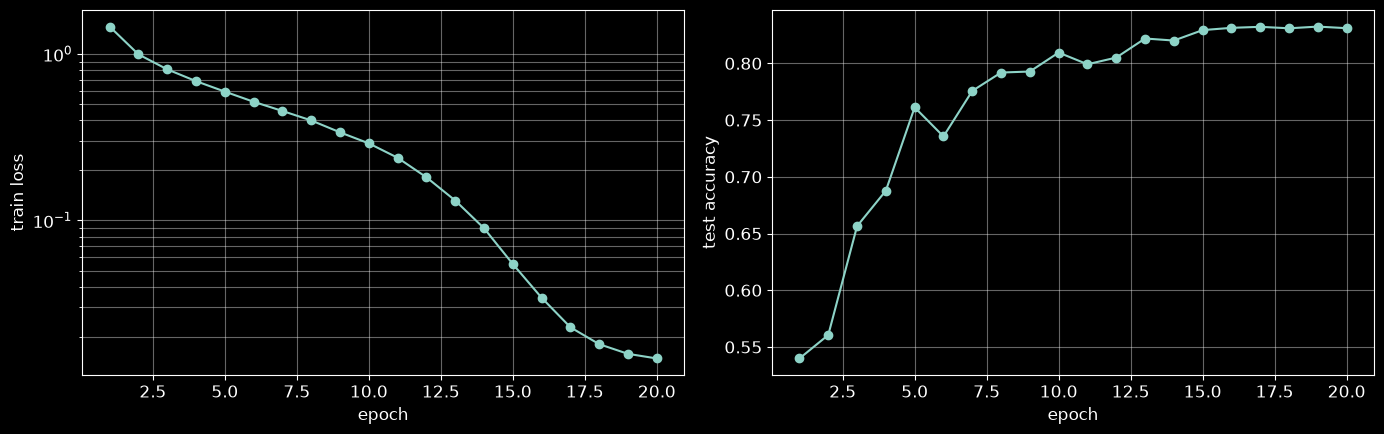

In [45]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

**Ответ:**

После 20 эпох ResNet-20 достигла train accuracy около 100% (на первых 10 000 тренировочных изображениях) и test accuracy 82,92%. Разрыв составил около 17,08 процентного пункта.

После 14-й эпохи test accuracy почти не изменялась (около 82-83%), тогда как train loss уменьшился примерно в 6 раз: с 0.0814 до 0.0128.

Дальнейшее уменьшение train loss почти перестало улучшать качество на тестовой выборке. Разрыв между train и test указывает на ограниченное обобщение, однако устойчивого снижения test accuracy не наблюдалось: на 20-й эпохе модель достигла нового максимума.


## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [46]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [47]:
ablation = {}
ablation = {}

for name, kwargs in ABLATIONS.items():
    set_seed(0)

    model = ResNetCIFAR(**kwargs)
    params = n_params(model)

    start = time.perf_counter()
    history = train_cifar(model, ABL_EPOCHS, LR, log=False)

    if device.type == 'cuda':
        torch.cuda.synchronize()

    minutes = (time.perf_counter() - start) / 60

    train_acc = accuracy(
        predict_logits(
            model,
            X_train[:10_000],
            transform=normalize
        ),
        Y_train[:10_000]
    )

    ablation[name] = dict(
        params=params,
        train_acc=train_acc,
        test_acc=history['test_acc'][-1],
        minutes=minutes,
        history=history
    )

    print(f'{name} completed in {minutes:.2f} min')

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')

plain-20 completed in 1.01 min
plain-56 completed in 3.32 min
model                    params  train acc  test acc  minutes
plain-20                269,722     0.8617    0.7919      1.0
plain-56                853,018     0.6465    0.6105      3.3


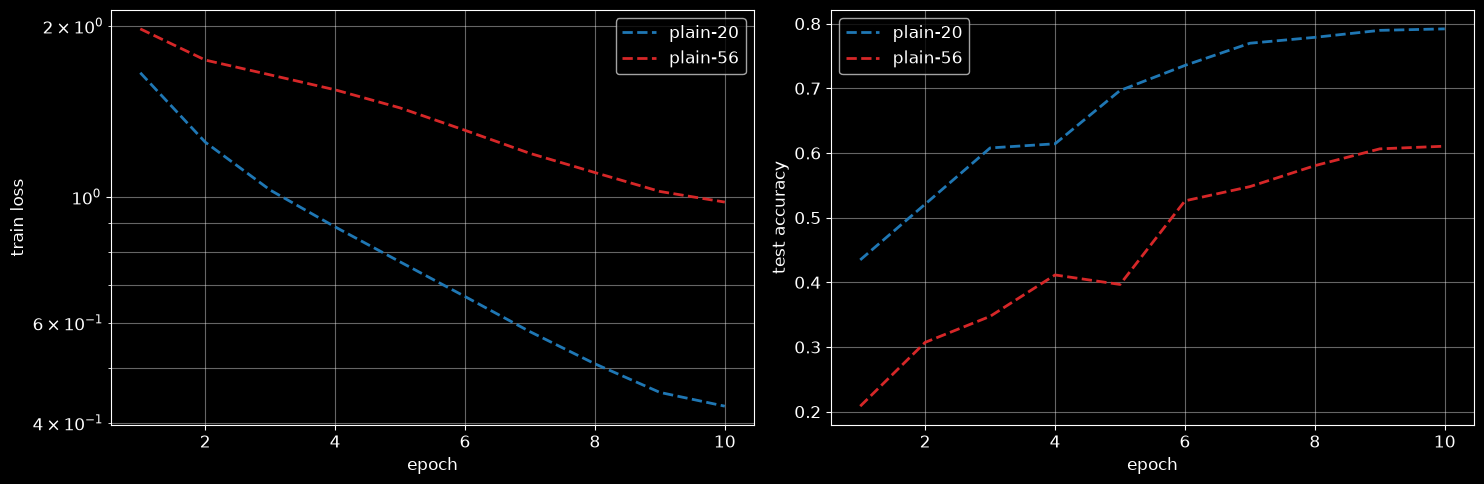

In [48]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

**Ответ:**
Увеличение глубины plain-сети с 20 до 56 слоёв привело к ухудшению результатов. Train accuracy уменьшилась с 84,31% до 55,53%; test accuracy - с 78,14% до 53,54%. У plain-56 loss на train оставался значительно выше на протяжении всех 10 эпох. Это показывает, что глубокую сеть без skip connections действительно сложнее обучать, т.к. качество ухудшилось и на тестовой, и на обучающей выборках. Если бы проблема была не в оптимизации, а в переобучении - мы бы наблюдали более высокую train accuracy при низкой test accuracy.

В качестве контрольного эксперимента можно было бы обучить ResNet-20 и ResNet-56 с residual connections при тех же гиперпараметрах и числе эпох. Так мы сможем проверить, насколько shortcut-соединения облегчают оптимизацию при увеличении глубины нейронной сети.

---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [49]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [50]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [51]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [52]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.913, 'FGSM, eps=0.1': 0.079, 'PGD-20, eps=0.1': 0.008}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [53]:
def pgd_l2(model, x, y, eps, alpha, steps):
    x = x.detach()
    x_adv = x.clone()

    for _ in range(steps):
        x_adv = x_adv.detach().requires_grad_(True)

        with torch.enable_grad():
            grad, = torch.autograd.grad(
                F.cross_entropy(model(x_adv), y),
                x_adv
            )

        grad_norm = grad.flatten(1).norm(
            p=2, dim=1
        ).view(-1, 1, 1, 1).clamp_min(1e-12)

        x_prime = x_adv.detach() + alpha * grad / grad_norm

        delta = x_prime - x
        delta_norm = delta.flatten(1).norm(
            p=2, dim=1
        ).view(-1, 1, 1, 1).clamp_min(1e-12)

        delta = delta * (eps / delta_norm).clamp(max=1.0)
        x_adv = (x + delta).clamp(0, 1)

    return x_adv.detach()

In [54]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.914; маленькое падение требует диагностики.


(0.914, 0.0)

In [55]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.913,
  0.5: 0.454,
  1.0: 0.092,
  1.5: 0.014,
  2.0: 0.0,
  3.0: 0.0,
  4.0: 0.0},
 0.007)

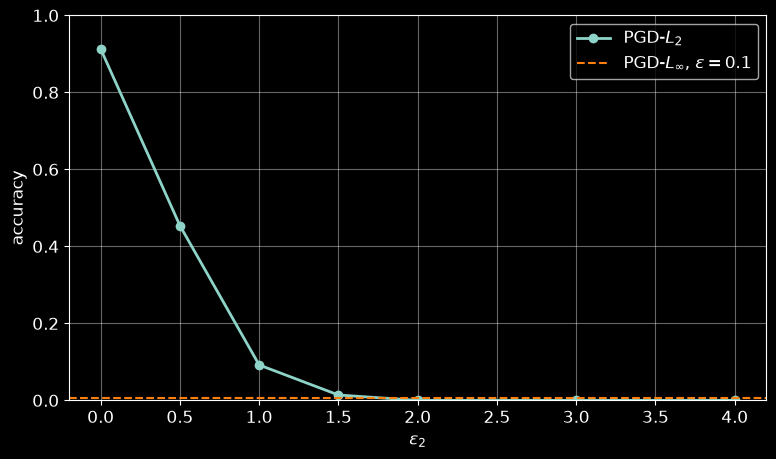

In [56]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=1.5, accuracy gap=0.007


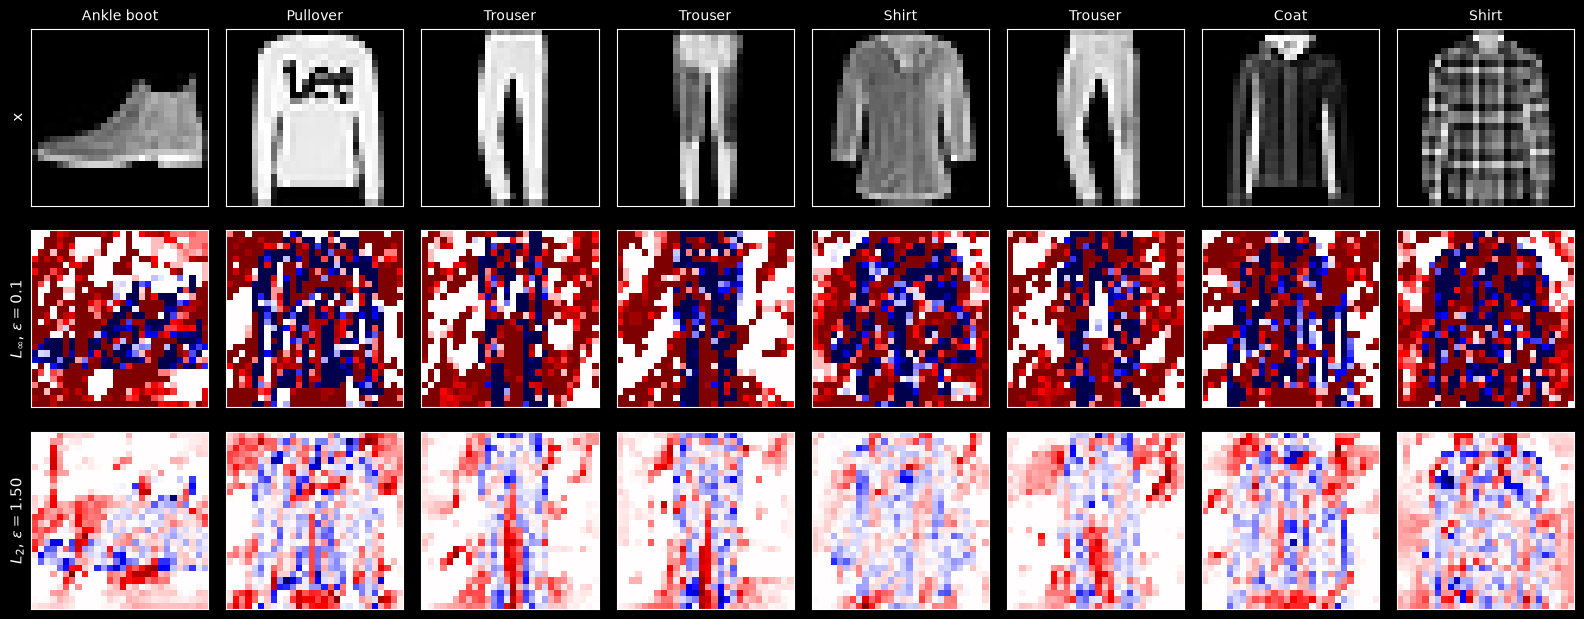

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.179
$L_2$, $\varepsilon=1.50$    L_inf = 0.266   L_2 = 1.492


In [57]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

**Ответ.**

Ближайшая к PGD-$L_\infty$ с $\varepsilon = 0.1$ точка сетки PGD-L2 соответствует $\varepsilon = 2.0$. Accuracy для $L_\infty$ составляет 0.006, для L2 - 0, поэтому разница равна 0.006

Фактическая L2-норма возмущения при $L_\infty$-атаке составила 2.162, для PGD-L2 - 1.987. Максимальное изменение отдельного пикселя составило 0.1 для $L_\infty$ и 0.377 для L2.

Из визуализации можно увидеть, что $L_\infty$-атака распределяет изменения по большому количеству пикселей, в то время как L2-атака допускает более сильные локальные изменения. Это связано с тем, что $L_\infty$ ограничивает каждую координату отдельно, а L2 - суммарную евклидову норму возмущения.

В PGD-L2 шаг выполняется в направлении градиента, нормированного по L2-норме. То есть координаты с большими по модулю компонентами градиента получают более сильные изменения. В PGD-$L_\infty$  используется знак градиента, из-за чего ненулевые компоненты на каждом шаге изменяются на одинаковую величину по модулю до проекции и ограничению пикселей.

В итоге, при почти одинаковой accuracy, атаки используют бюджет возмущений по-разному.


## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [58]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        # ваш код
        raise NotImplementedError


    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        # ваш код
        raise NotImplementedError

In [59]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

In [60]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

**Ответ.** 

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [61]:
if ATTACK_TRACK == 'transfer':
    set_seed(1)
    model_b = train_fm(SmallCNN())

    set_seed(2)
    model_mlp = train_fm(nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 512),
        nn.ReLU(),
        nn.Linear(512, 512),
        nn.ReLU(),
        nn.Linear(512, 10)
    ))

    victims = {
        'model A (source)': model_a,
        'model B': model_b,
        'MLP': model_mlp
    }

    for model in victims.values():
        model.eval()
        model.zero_grad(set_to_none=True)

    attacks = {
        'clean': None,
        'FGSM': lambda x, y: fgsm_attack(model_a, x, y, eps=0.1),
        'PGD-20': lambda x, y: pgd(model_a, x, y, eps=0.1)
    }

    transfer = {}
    torch.manual_seed(0)

    for attack_name, attack in attacks.items():
        correct = {name: 0 for name in victims}

        for i in range(0, len(XF_test), 128):
            x = XF_test[i:i + 128]
            y = YF_test[i:i + 128]

            x_adv = attack(x, y) if attack is not None else x

            with torch.no_grad():
                for name, model in victims.items():
                    pred = model(x_adv).argmax(dim=1)
                    correct[name] += (pred == y).sum().item()

        transfer[attack_name] = {
            name: count / len(XF_test)
            for name, count in correct.items()
        }

    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

    print('\nAccuracy drops:')
    for attack in ('FGSM', 'PGD-20'):
        drops = {
            name: transfer['clean'][name] - transfer[attack][name]
            for name in victims
        }
        print(attack, drops)

          model A (source)           model B               MLP
clean                0.913             0.916             0.879
FGSM                 0.079             0.263             0.572
PGD-20               0.006             0.146             0.578

Accuracy drops:
FGSM {'model A (source)': 0.8340000000000001, 'model B': 0.653, 'MLP': 0.30700000000000005}
PGD-20 {'model A (source)': 0.907, 'model B': 0.77, 'MLP': 0.30100000000000005}


**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.**

Атаки генерировались на Model A и затем применялись ко всем трём моделям без дополнительной оптимизации.

На исходной Model A атака FGSM снизила accuracy с 91.6% до 8.1% (падение на 83.5 пункта), а PGD-20 - до 0.7% (падение на 90.9).

На Model B с той же архитектурой, но другой инициализацией, FGSM снизила accuracy с 91.1% до 26.5% (64.6 пункта), а PGD-20  -  до 14.7% (76.4 пункта).

На MLP обе атаки снизили accuracy с 87.9% до 57.7% (на 30.2 процентного пункта)

В результате - в нашем эксперименте атаки лучше переносятся между двумя CNN, чем с CNN на MLP. Это может быть связано со сходством архитектур и используемых признаков. При этом PGD-20 переносится на Model B лучше FGSM, но для MLP обе атаки дают одинаковый результат.

Один seed не позволяет сделать общий вывод о превосходстве архитектуры или атаки, поскольку результаты могут зависеть от случайной инициализации, порядка обучения и особенностей полученных весов.

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [62]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [63]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = dict(clean=[], fgsm=[], pgd=[])

    for epoch in range(epochs):
        total_loss = 0.0

        for x, y in iterate_batches(XF_train, YF_train, 128):
            model.eval()
            x_adv = attack(model, x, y, eps).detach()
            model.train()

            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(model(x_adv), y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(y)

        model.eval()
        x_eval, y_eval = XF_test[:1000], YF_test[:1000]

        history['clean'].append(
            attack_accuracy(model, x_eval, y_eval, batch_size=128)
        )
        history['fgsm'].append(
            attack_accuracy(model, x_eval, y_eval, fgsm_attack, batch_size=128, eps=eps)
        )
        history['pgd'].append(
            attack_accuracy(model, x_eval, y_eval, pgd, batch_size=128, eps=eps)
        )

        if log:
            print(
                f"Epoch {epoch + 1}/{epochs}: "
                f"loss={total_loss / len(XF_train):.4f}, "
                f"clean={history['clean'][-1]:.3f}, "
                f"FGSM={history['fgsm'][-1]:.3f}, "
                f"PGD-20={history['pgd'][-1]:.3f}"
            )

    model.eval()
    model.zero_grad(set_to_none=True)
    return history

In [64]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
Epoch 1/5: loss=1.0170, clean=0.798, FGSM=0.693, PGD-20=0.665
Epoch 2/5: loss=0.8223, clean=0.807, FGSM=0.702, PGD-20=0.660
Epoch 3/5: loss=0.7739, clean=0.824, FGSM=0.719, PGD-20=0.688
Epoch 4/5: loss=0.7422, clean=0.830, FGSM=0.738, PGD-20=0.707
Epoch 5/5: loss=0.7202, clean=0.823, FGSM=0.727, PGD-20=0.710


In [65]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.913   0.148   0.009   0.000   0.000   0.000
PGD-AT       0.823   0.768   0.710   0.476   0.155   0.001


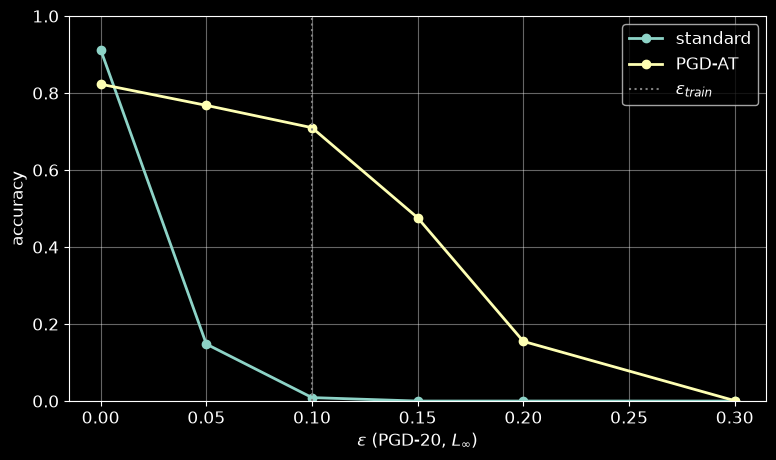

In [66]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

**Ответ.**

После adversarial training clean accuracy снизилась с 91.6% до 82.7%, то есть на 8.9 процентного пункта. При этом устойчивость к PGD-20 с эпсилон = 0.1 выросла: accuracy увеличилась с 0.7% до 71.1%.

При увеличении $\varepsilon$ выше тренировочного значения устойчивость постепенно снижается. При $\varepsilon = 0.15$ accuracy составляет 46.5%, при $\varepsilon = 0.2$ - 13.5%, а при $\varepsilon = 0.3$ практически падает до нуля. Можно сделать вывод, что защита хорошо работает вблизи тренировочного бюджета атаки, но не гарантирует устойчивость к более сильным возмущениям.

PGD-7 adversarial training требует примерно 8 вычислений forward и градиентов на батч: 7 для построения атаки и ещё одно для обновления модели. Поэтому он существенно дороже обычного обучения, в котором требуется только один forward/backward.

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [67]:
def sanity_checks(model, x, y, eps):
    model.eval()
    counts = dict(fgsm=0, pgd20=0, pgd100_x5=0, eps_1=0)

    for start in range(0, len(x), 128):
        xb = x[start:start + 128]
        yb = y[start:start + 128]

        with torch.no_grad():
            clean_ok = model(xb).argmax(1).eq(yb)

        x_fgsm = fgsm_attack(model, xb, yb, eps)
        x_pgd20 = pgd_attack(
            model, xb, yb, eps,
            alpha=2.5 * eps / 20,
            steps=20,
            random_start=True
        )
        x_eps1 = pgd_attack(
            model, xb, yb, 1.0,
            alpha=2.5 / 20,
            steps=20,
            random_start=True
        )

        with torch.no_grad():
            counts['fgsm'] += (
                clean_ok & model(x_fgsm).argmax(1).eq(yb)
            ).sum().item()

            counts['pgd20'] += (
                clean_ok & model(x_pgd20).argmax(1).eq(yb)
            ).sum().item()

            counts['eps_1'] += (
                clean_ok & model(x_eps1).argmax(1).eq(yb)
            ).sum().item()

        robust = clean_ok.clone()

        for _ in range(5):
            x_adv = pgd_attack(
                model, xb, yb, eps,
                alpha=2.5 * eps / 100,
                steps=100,
                random_start=True
            )

            with torch.no_grad():
                robust &= model(x_adv).argmax(1).eq(yb)

        counts['pgd100_x5'] += robust.sum().item()

    return {key: count / len(x) for key, count in counts.items()}

In [68]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.090      0.012      0.012      0.000
PGD-AT                      0.766      0.746      0.734      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

**Ответ.**

У стандартной модели FGSM снизила accuracy до 9.4%, PGD-20 - до 1.2%, а PGD-100 с пятью случайными перезапусками - до 0.8%. Можно сделать вывод, что модель практически неустойчива к рассматриваемым атакам.

Для модели с adversarial training accuracy составила 75.0%, 73.8% и 72.3% соответственно. Усиление PGD-20 до PGD-100 с пятью перезапусками снизило accuracy всего на 1.5 процентного пункта, первоначальная оценка устойчивости не выглядит сильно завышенной.

При эпсилон = 1 accuracy обеих моделей упала до нуля.

Результаты не дают явных признаков gradient masking, так как усиление атаки приводит к ожидаемому снижению accuracy, а не к её увеличению. Однако полностью исключить gradient masking по этим проверкам нельзя. Для диагностики можно использовать другие атаки, например AutoAttack, или проверить устойчивость при увеличении числа шагов и случайных перезапусков.

- Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все sanity checks?

Да, такая модель может успешно пройти проверки корректности вычислений, но считаться робастной по этим результатам не должна. Большой разрыв между FGSM и PGD может указывать на слабость одношаговой атаки или gradient masking. Поэтому для оценки устойчивости нужны более сильные атаки, а не только FGSM.

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [69]:
def input_gradient(model, x, y):
    grads = []

    with torch.enable_grad():
        for i in range(len(x)):
            xi = x[i:i + 1].detach().clone().requires_grad_(True)
            logit = model(xi)[0, y[i]]
            grad, = torch.autograd.grad(logit, xi)
            grads.append(grad.abs().detach())

    return torch.cat(grads, dim=0)


def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()

In [70]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5786540508270264, 'PGD-AT': 0.21004751324653625}

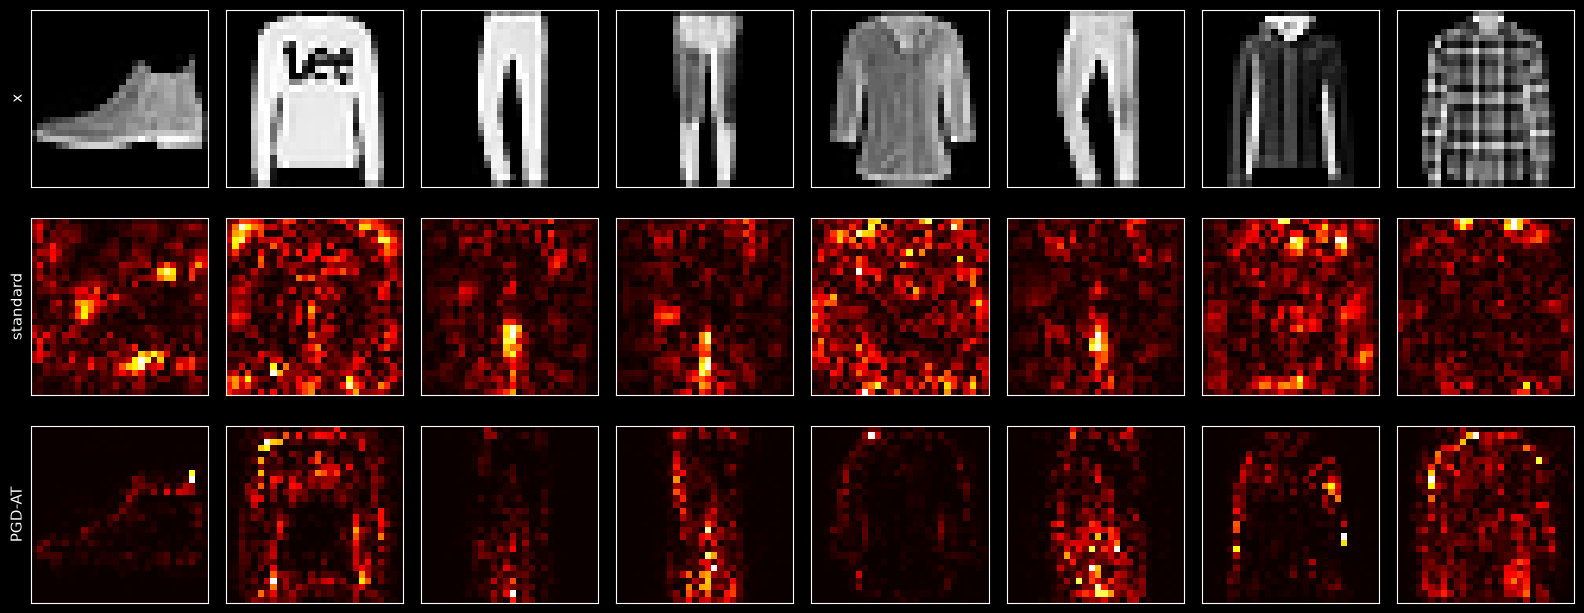

In [71]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

**Ответ.**


Карты стандартной модели выглядят более шумными: яркие участки встречаются как на объектах, так и на фоне. У PGD-AT модели градиенты более структурированы и чаще сосредоточены на контурах и деталях одежды.

Доля фоновых пикселей составляет 49.8%. При этом у стандартной модели на фон приходится 57.56% суммарной массы градиента, а у PGD-AT  -  только 21.40%.

Это согласуется с результатами атак: при PGD-20 с эпсилон = 0.1 accuracy робастной модели составила 71.1%, тогда как у стандартной - 0.7%.

saliency-карта показывает локальную чувствительность логита к пикселям, при этом не гарантирует сохранение предсказания при возмущениях. Для оценки robustness нужны отдельные проверки сильными атаками.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [72]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'resnet20.pt']


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [73]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        return torch.autograd.grad(
            grads,
            params,
            grad_outputs=v,
            retain_graph=True
        )


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [74]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [75]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

eta=0.05 | loss=0.11012 | sharpness=37.999 | 2/eta=40.000
eta=0.2 | loss=0.07260 | sharpness=10.949 | 2/eta=10.000
eta=0.5 | loss=0.03630 | sharpness=4.270 | 2/eta=4.000


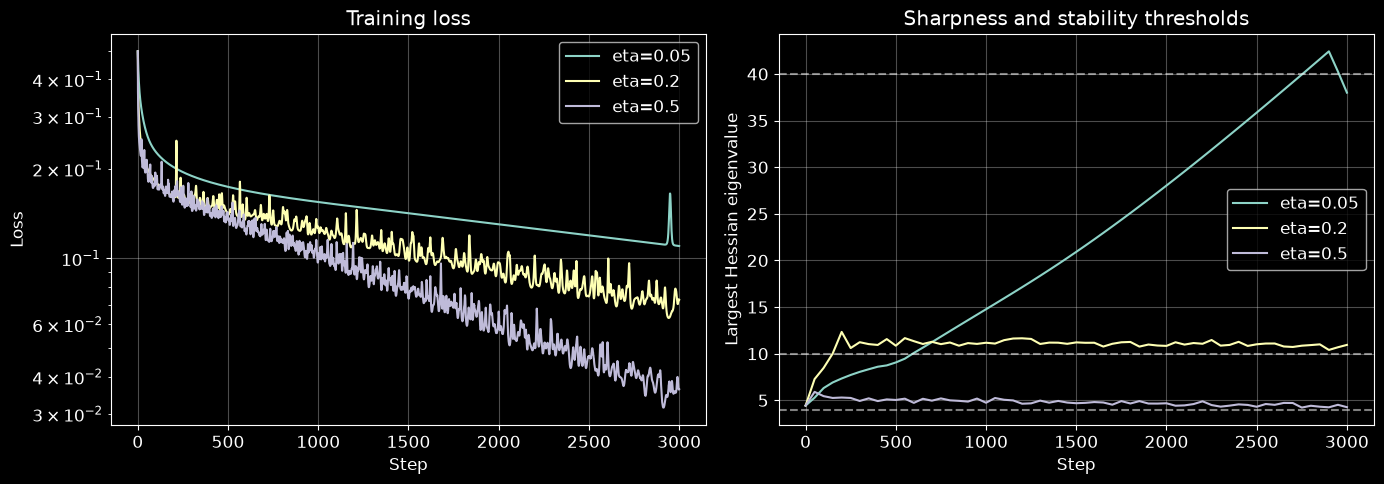

In [76]:
if '7.1' in BONUS_TASKS:
    eos_results = {}

    for eta in [0.05, 0.2, 0.5]:
        model = make_tanh_mlp(seed=0)
        optimizer = torch.optim.SGD(model.parameters(), lr=eta)

        history = dict(step=[], loss=[], sharp_steps=[], sharpness=[])

        for step in range(EOS_STEPS + 1):
            if step % 50 == 0:
                lam, _ = top_eigenvalue(
                    lambda: mse_loss(model),
                    model.parameters(),
                    iters=12
                )

                history['sharp_steps'].append(step)
                history['sharpness'].append(lam)

            loss = mse_loss(model)
            history['step'].append(step)
            history['loss'].append(loss.item())

            if step == EOS_STEPS:
                break

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

        eos_results[eta] = history

        print(
            f'eta={eta} | '
            f'loss={history["loss"][-1]:.5f} | '
            f'sharpness={history["sharpness"][-1]:.3f} | '
            f'2/eta={2 / eta:.3f}'
        )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    for eta, history in eos_results.items():
        axes[0].plot(
            history['step'],
            history['loss'],
            label=f'eta={eta}'
        )

        axes[1].plot(
            history['sharp_steps'],
            history['sharpness'],
            label=f'eta={eta}'
        )

        axes[1].axhline(
            2 / eta,
            linestyle='--',
            alpha=0.5
        )

    axes[0].set(title='Training loss', xlabel='Step', ylabel='Loss')
    axes[0].set_yscale('log')

    axes[1].set(
        title='Sharpness and stability thresholds',
        xlabel='Step',
        ylabel='Largest Hessian eigenvalue'
    )

    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plt.show()

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.**
В эксперименте для всех трёх lr sharpness приблизилась к границе $2/\eta$. При $\eta$ = 0.05 она постепенно выросла примерно до 38 при пороге 40 (правда в конце наблюдается небольшой "всплеск"). Для $\eta$ = 0.2 и $\eta$ = 0.5 значения стабилизировались около 11 и 4.27 при порогах 10 и 4 соответственно.

При этом loss продолжал снижаться, причём быстрее всего при $\eta$ = 0.5. Можем наблюдать эффект Edge of Stability. В том смысле, что во время обучения sharpness может достигать или немного превышать порог устойчивости, но сеть при этом продолжает оптимизироваться.

Критерий $\eta$ < 2/$\lambda_{\max}$ относится только к градиентному спуску на фиксированной квадратичной функции с положительно определённым гессианом. В нелинейной сети гессиан меняется при обновлении параметров, поэтому кратковременное превышение порога не обязательно приводит к расходимости.

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [77]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        kh, kw = weight.shape[-2:]
        xpad = F.pad(x, (padding, padding, padding, padding))

        b, cin, hp, wp = xpad.shape
        cout = weight.shape[0]
        size = (hp + kh - 1, wp + kw - 1)

        x_f = torch.fft.rfft2(
            xpad.reshape(b, groups, cin // groups, hp, wp),
            s=size
        )

        w_f = torch.fft.rfft2(
            weight.flip(-2, -1).reshape(
                groups, cout // groups, cin // groups, kh, kw
            ),
            s=size
        )

        prod = torch.einsum('bgcij,gocij->bgoij', x_f, w_f)

        out = torch.fft.irfft2(prod, s=size)
        out = out[..., kh - 1:hp:stride, kw - 1:wp:stride]
        out = out.reshape(b, cout, out.shape[-2], out.shape[-1])

        if bias is not None:
            out = out + bias.reshape(1, -1, 1, 1)

        return out

In [78]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

**Ответ.**

При stride s по обеим координатам сохраняется примерно 1/s^2 вычисленных значений, поэтому доля отброшенных составляет 1 - 1/s^2. Например, при stride 2 отбрасывается около 75% результатов, а при stride 3 - около 88.9%.

При этом FFT-свёртка может быть быстрее прямой при больших ядрах и изображениях, т.к. позволяет заменить свёртку поэлементным умножением в частотной области. Дополнительные затраты на FFT, обратное преобразование и вычисление впоследствии отброшенных значений могут сделать FFT более тяжёлым по вычислениям, чем обычные свёртки

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [79]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        a, b, c = coeffs

        X = M.bfloat16()
        transposed = X.shape[0] > X.shape[1]

        if transposed:
            X = X.T

        X = X / X.norm().clamp_min(1e-7)

        for _ in range(steps):
            A = X @ X.T
            B = torch.addmm(A, A, A, beta=b, alpha=c)
            X = torch.addmm(X, B, X, beta=a)

        return (X.T if transposed else X).to(M.dtype)


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']

                for p in group['params']:
                    if p.grad is None:
                        continue

                    state = self.state[p]

                    if 'momentum_buffer' not in state:
                        state['momentum_buffer'] = torch.zeros_like(p)

                    buf = state['momentum_buffer']
                    buf.lerp_(p.grad, 1 - mu)

                    update = p.grad.lerp(buf, mu)

                    m = p.shape[0]
                    n = p.numel() // m

                    ortho = newton_schulz(update.reshape(m, n))
                    scale = math.sqrt(max(1.0, m / n))

                    p.add_(
                        ortho.reshape_as(p),
                        alpha=-group['lr'] * scale
                    )

In [80]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)


### Дополнительный эксперимент - адаптация SCALE для CNN

Ради интереса снова вернёмся к статье [A Minimalist Optimizer Design for LLM Pretraining](https://arxiv.org/abs/2506.16659) и попробуем адаптировать SCALE для свёрточной сети ResNet-20.

Основная идея SCALE - отказаться от хранения моментов градиентов для большинства матриц, заменив адаптивное обновление нормализацией градиентов. Momentum сохраняется только для последнего слоя, а одномерные параметры обновляются с помощью AdamW. (краткое напоминание)

**Адаптация для свёрточных весов**

Вес свёртки имеет форму:

$$
W \in \mathbb{R}^{C_{\text{out}}\times C_{\text{in}}\times k_h\times k_w}.
$$

Развернём каждый фильтр в строку матрицы:

$$
W_{\text{mat}}\in\mathbb{R}^{C_{\text{out}}\times d},
\qquad d=C_{\text{in}}k_hk_w.
$$

Для каждой строки градиента вычисляем RMS:

$$
r_i=\sqrt{\frac{1}{d}\sum_{j=1}^{d}G_{ij}^{2}}.
$$

Затем нормализуем градиент:

$$
\widetilde G_{ij}=
\frac{G_{ij}}{\max(r_i,\varepsilon)}.
$$

Обновление параметров с decoupled weight decay:

$$
W_{t+1}=(1-\eta\lambda)W_t-\eta\widetilde G_t.
$$

Таким образом, для каждого выходного фильтра масштаб обновления нормализуется независимо от остальных фильтров. При этом не требуется хранить первый и второй моменты градиента.

**Momentum для классификационной головы**

Для последнего линейного слоя `fc` сначала накапливаем momentum:

$$
M_t=\beta_1M_{t-1}+(1-\beta_1)G_t.
$$

После этого применяем аналогичную построчную RMS-нормализацию:

$$
\widetilde M_{ij}=
\frac{M_{ij}}{
\max\left(
\sqrt{\frac{1}{d}\sum_{k=1}^{d}M_{ik}^{2}},
\varepsilon
\right)
}.
$$

И обновляем веса:

$$
W_{t+1}=(1-\eta\lambda)W_t-\eta\widetilde M_t.
$$

Одномерные параметры, включая параметры BatchNorm и смещения, обновляются по AdamW-подобной схеме без weight decay.

Это не совсем точная копия исходного LLM-оптимизатора, а его адаптированная под свёртки версия. В этом коротком опыте она показала несколько более высокую test accuracy, чем AdamW. Для более строгого сравнения нужно отдельно подобрать гиперпараметры и повторить эксперименты с разными seed.


In [81]:
if '7.3' in BONUS_TASKS:
    class CNNScale(torch.optim.Optimizer):
        def __init__(self, model, lr=3e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.05):
            super().__init__(
                model.parameters(),
                dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)
            )
            self.head_id = id(model.fc.weight)

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                lr = group['lr']
                beta1, beta2 = group['betas']
                eps = group['eps']
                wd = group['weight_decay']

                for p in group['params']:
                    if p.grad is None:
                        continue

                    g = p.grad
                    state = self.state[p]

                    if p.ndim <= 1:
                        if 'm' not in state:
                            state['step'] = 0
                            state['m'] = torch.zeros_like(p)
                            state['v'] = torch.zeros_like(p)

                        state['step'] += 1
                        t = state['step']

                        state['m'].lerp_(g, 1 - beta1)
                        state['v'].mul_(beta2).addcmul_(g, g, value=1 - beta2)

                        m = state['m'] / (1 - beta1 ** t)
                        v = state['v'] / (1 - beta2 ** t)

                        p.addcdiv_(m, v.sqrt().add(eps), value=-lr)
                        continue

                    if id(p) == self.head_id:
                        if 'momentum' not in state:
                            state['momentum'] = torch.zeros_like(p)

                        state['momentum'].lerp_(g, 1 - beta1)
                        g = state['momentum']

                    flat = g.reshape(g.shape[0], -1)
                    rms = flat.square().mean(dim=1, keepdim=True).sqrt().clamp_min(eps)
                    update = (flat / rms).reshape_as(p)

                    p.mul_(1 - lr * wd)
                    p.add_(update, alpha=-lr)

In [82]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02

    set_seed(0)
    model_muon = ResNetCIFAR(20).to(device)

    conv_params = []
    other_decay = []
    other_no_decay = []

    for p in model_muon.parameters():
        if p.ndim == 4:
            conv_params.append(p)
        elif p.ndim > 1:
            other_decay.append(p)
        else:
            other_no_decay.append(p)

    muon_optimizer = ConvMuon(conv_params, lr=MUON_LR)

    adam_optimizer = MyAdamW(
        [
            {'params': other_decay, 'weight_decay': 0.05},
            {'params': other_no_decay, 'weight_decay': 0.0}
        ],
        lr=LR
    )

    total_steps = EPOCHS * math.ceil(len(X_train) / 256)

    muon_scheduler = torch.optim.lr_scheduler.LambdaLR(
        muon_optimizer,
        lambda t: cosine_lr(t, total_steps)
    )

    adam_scheduler = torch.optim.lr_scheduler.LambdaLR(
        adam_optimizer,
        lambda t: cosine_lr(t, total_steps)
    )

    hist_muon = dict(train_loss=[], test_acc=[])

    for epoch in range(EPOCHS):
        model_muon.train()
        total_loss = 0.0

        for x, y in iterate_batches(
            X_train, Y_train, 256,
            shuffle=True, transform=normalize
        ):
            muon_optimizer.zero_grad(set_to_none=True)
            adam_optimizer.zero_grad(set_to_none=True)

            loss = F.cross_entropy(model_muon(x), y)
            loss.backward()

            muon_optimizer.step()
            adam_optimizer.step()

            muon_scheduler.step()
            adam_scheduler.step()

            total_loss += loss.item() * len(y)

        train_loss = total_loss / len(X_train)

        test_logits = predict_logits(
            model_muon,
            X_test,
            batch_size=512,
            transform=normalize
        )

        test_acc = accuracy(test_logits, Y_test)

        hist_muon['train_loss'].append(train_loss)
        hist_muon['test_acc'].append(test_acc)

        print(
            f'Epoch {epoch + 1}/{EPOCHS} | '
            f'loss={train_loss:.4f} | '
            f'test acc={test_acc:.4f}'
        )

    hist_adamw = history_cifar

    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(
            f'{name:<10}'
            f'{hist["train_loss"][-1]:>12.4f}'
            f'{hist["test_acc"][-1]:>10.4f}'
        )

Epoch 1/20 | loss=1.1493 | test acc=0.6790
Epoch 2/20 | loss=0.6751 | test acc=0.7466
Epoch 3/20 | loss=0.5105 | test acc=0.8046
Epoch 4/20 | loss=0.4039 | test acc=0.8120
Epoch 5/20 | loss=0.3224 | test acc=0.8204
Epoch 6/20 | loss=0.2475 | test acc=0.8005
Epoch 7/20 | loss=0.1864 | test acc=0.8261
Epoch 8/20 | loss=0.1354 | test acc=0.8286
Epoch 9/20 | loss=0.0908 | test acc=0.8256
Epoch 10/20 | loss=0.0654 | test acc=0.8360
Epoch 11/20 | loss=0.0410 | test acc=0.8345
Epoch 12/20 | loss=0.0289 | test acc=0.8365
Epoch 13/20 | loss=0.0184 | test acc=0.8408
Epoch 14/20 | loss=0.0101 | test acc=0.8440
Epoch 15/20 | loss=0.0054 | test acc=0.8463
Epoch 16/20 | loss=0.0031 | test acc=0.8481
Epoch 17/20 | loss=0.0018 | test acc=0.8491
Epoch 18/20 | loss=0.0011 | test acc=0.8496
Epoch 19/20 | loss=0.0008 | test acc=0.8514
Epoch 20/20 | loss=0.0007 | test acc=0.8517
            train loss  test acc
AdamW           0.0148    0.8310
Muon            0.0007    0.8517


In [83]:
if '7.3' in BONUS_TASKS:
    SCALE_LR = 3e-3

    set_seed(0)
    model_scale = ResNetCIFAR(20).to(device)

    optimizer = CNNScale(
        model_scale,
        lr=SCALE_LR,
        weight_decay=0.05
    )

    total_steps = EPOCHS * math.ceil(len(X_train) / 256)

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lambda t: cosine_lr(t, total_steps)
    )

    hist_scale = dict(train_loss=[], test_acc=[])

    for epoch in range(EPOCHS):
        model_scale.train()
        total_loss = 0.0

        for x, y in iterate_batches(
            X_train, Y_train, 256,
            shuffle=True, transform=normalize
        ):
            optimizer.zero_grad(set_to_none=True)

            loss = F.cross_entropy(model_scale(x), y)
            loss.backward()

            optimizer.step()
            scheduler.step()

            total_loss += loss.item() * len(y)

        hist_scale['train_loss'].append(total_loss / len(X_train))

        logits = predict_logits(
            model_scale, X_test,
            batch_size=512, transform=normalize
        )

        test_acc = accuracy(logits, Y_test)
        hist_scale['test_acc'].append(test_acc)

        print(
            f'Epoch {epoch + 1}/{EPOCHS} | '
            f'loss={hist_scale["train_loss"][-1]:.4f} | '
            f'acc={test_acc:.4f}'
        )

Epoch 1/20 | loss=1.5899 | acc=0.4478
Epoch 2/20 | loss=1.0494 | acc=0.5978
Epoch 3/20 | loss=0.8213 | acc=0.6202
Epoch 4/20 | loss=0.6858 | acc=0.6888
Epoch 5/20 | loss=0.5837 | acc=0.6451
Epoch 6/20 | loss=0.5095 | acc=0.7241
Epoch 7/20 | loss=0.4421 | acc=0.7842
Epoch 8/20 | loss=0.3806 | acc=0.7536
Epoch 9/20 | loss=0.3200 | acc=0.7827
Epoch 10/20 | loss=0.2640 | acc=0.7976
Epoch 11/20 | loss=0.2110 | acc=0.7628
Epoch 12/20 | loss=0.1595 | acc=0.8103
Epoch 13/20 | loss=0.1138 | acc=0.8042
Epoch 14/20 | loss=0.0771 | acc=0.7857
Epoch 15/20 | loss=0.0485 | acc=0.8269
Epoch 16/20 | loss=0.0282 | acc=0.8233
Epoch 17/20 | loss=0.0155 | acc=0.8242
Epoch 18/20 | loss=0.0092 | acc=0.8265
Epoch 19/20 | loss=0.0063 | acc=0.8258
Epoch 20/20 | loss=0.0051 | acc=0.8243


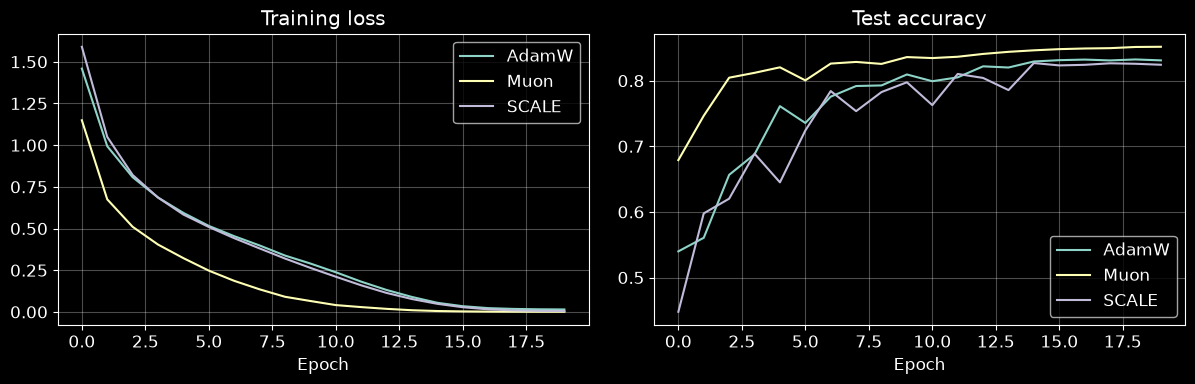

Optimizer      Train loss     Test acc
AdamW              0.0148       0.8310
Muon               0.0007       0.8517
SCALE              0.0051       0.8243


In [84]:
if '7.3' in BONUS_TASKS:
    histories = {
        'AdamW': history_cifar,
        'Muon': hist_muon,
        'SCALE': hist_scale
    }

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for name, hist in histories.items():
        axes[0].plot(hist['train_loss'], label=name)
        axes[1].plot(hist['test_acc'], label=name)

    axes[0].set(title='Training loss', xlabel='Epoch')
    axes[1].set(title='Test accuracy', xlabel='Epoch')

    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend()

    plt.tight_layout()
    plt.show()

    print(f'{"Optimizer":<12} {"Train loss":>12} {"Test acc":>12}')

    for name, hist in histories.items():
        print(
            f'{name:<12} '
            f'{hist["train_loss"][-1]:>12.4f} '
            f'{hist["test_acc"][-1]:>12.4f}'
        )

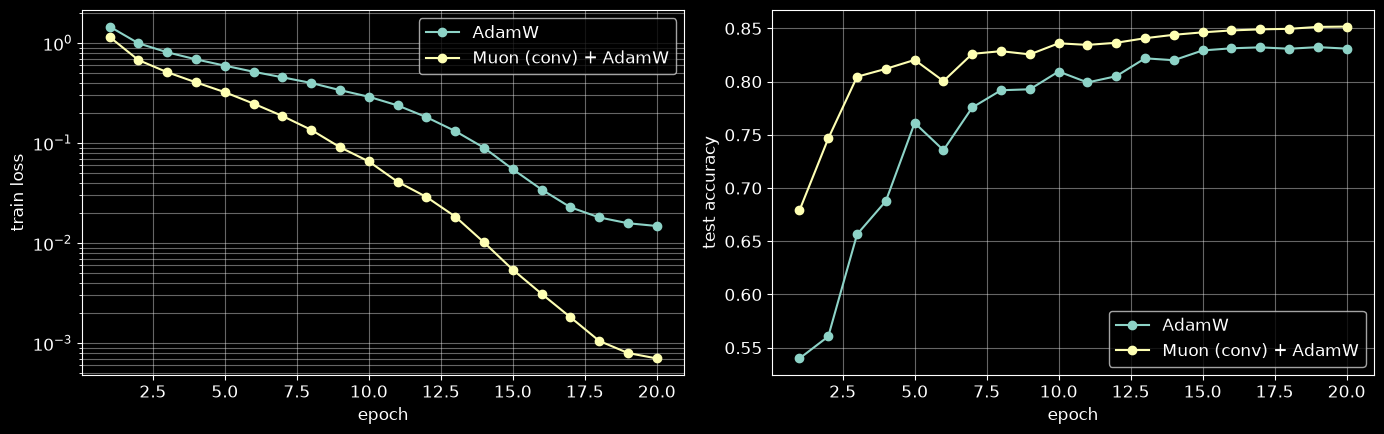

In [85]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.**

В эксперименте Muon + AdamW заметно быстрее снижал тренировочный loss, чем обычный AdamW. После 20 эпох loss составил 0.0007 против 0.0147. Test accuracy также оказалась выше: 85.30% против 82.22%, то есть разница составила 3.08 процентного пункта.

При использовании FP32 AdamW хранит два состояния на каждый параметр - первый и второй моменты градиента, суммарно около 8 байт на параметр. Muon хранит только momentum, то есть около 4 байт на параметр. В нашей гибридной реализации это относится к свёрточным весам, поскольку остальные параметры обновляются через AdamW.

Также ради интереса была сделана попытка адаптировать SCALE (исходно LLM-оптимизатор) для CNN. Модель с таким оптимизатором достигла train loss 0.0055 и test accuracy 83.04%, получив примерно средний результат между AdamW и Muon. Для свёрточных весов CNNScale не хранит моменты градиента, а momentum сохраняется только для классификационной головы. Если продолжать эту идею, то также стоило бы сравнивать результаты с обычным SGD.

При этом, эксперимент сравнивает оптимизаторы по фиксированным настройкам обучения, при этом у них различаются lr и использование weight decay, поэтому результаты для CNNScale остаются неоднозначными.

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [86]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [87]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

{'clean': 0.914, 'L0, k=5': 0.618}
standard    0.914  0.892  0.842  0.764  0.618  0.404  0.166  0.050
PGD-AT      0.840  0.812  0.786  0.766  0.720  0.622  0.448  0.292


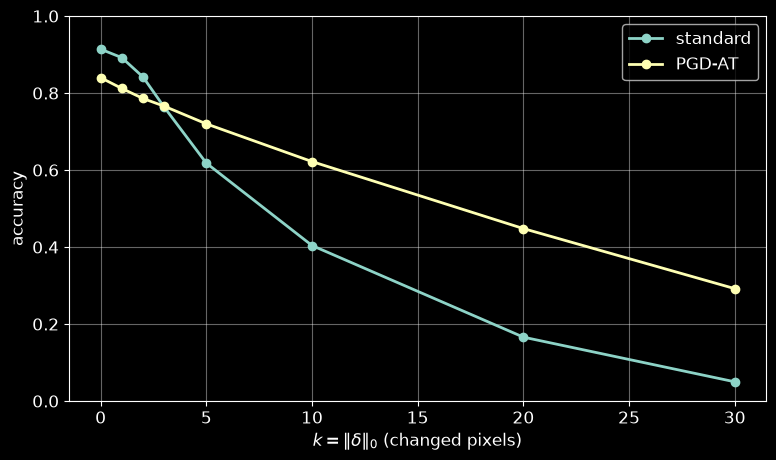

In [88]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

**Ответ.**

В эксперименте PGD-AT показала лучшую устойчивость к L0-атаке при достаточно большом количестве изменённых пикселей, хотя обучалась защищаться от $L_\infty$-возмущений.

Получилось следующее:
При k = 5 accuracy стандартной модели снизилась с 91.4% до 61.4%, а PGD-AT - с 84.2% до 71.6%. При k = 30 стандартная модель сохранила только 5.8% accuracy, тогда как PGD-AT - 30.4%.

В результате adversarial training частично улучшила устойчивость и к другому типу возмущений.

$L_\infty$-шар с $\varepsilon$ = 0.1 ограничивает изменение каждого пикселя величиной 0.1, а L0-атака ограничивает только количество изменённых пикселей. Поэтому она может изменить отдельный пиксель с 0 до 1, что выходит за пределы тренировочного $L_\infty$-шара.

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [89]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

FGSM
Epoch 1/5: loss=1.2044, clean=0.735, FGSM=0.635, PGD-20=0.056
Epoch 2/5: loss=0.7769, clean=0.633, FGSM=0.844, PGD-20=0.005
Epoch 3/5: loss=0.2319, clean=0.511, FGSM=0.959, PGD-20=0.000
Epoch 4/5: loss=0.1259, clean=0.546, FGSM=0.961, PGD-20=0.000
Epoch 5/5: loss=0.1263, clean=0.529, FGSM=0.958, PGD-20=0.001
FGSM-RS
Epoch 1/5: loss=1.1906, clean=0.764, FGSM=0.615, PGD-20=0.368
Epoch 2/5: loss=0.8955, clean=0.772, FGSM=0.654, PGD-20=0.422
Epoch 3/5: loss=0.7808, clean=0.794, FGSM=0.687, PGD-20=0.443
Epoch 4/5: loss=0.7116, clean=0.814, FGSM=0.714, PGD-20=0.463
Epoch 5/5: loss=0.6687, clean=0.801, FGSM=0.724, PGD-20=0.466


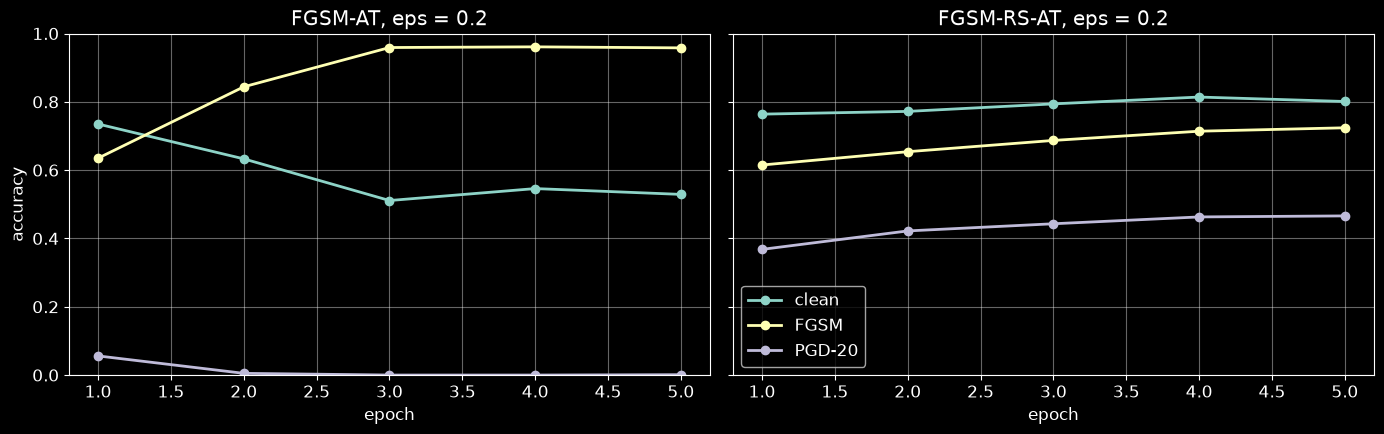

In [90]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [91]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

{'FGSM': {'fgsm': 0.51953125, 'pgd20': 0.0, 'pgd100_x5': 0.0, 'eps_1': 0.0}, 'FGSM-RS': {'fgsm': 0.73828125, 'pgd20': 0.48046875, 'pgd100_x5': 0.43359375, 'eps_1': 0.0}}


**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

**Ответ.**

При обычном FGSM adversarial training модель почти не получила устойчивости к PGD: уже на первой эпохе PGD-20 accuracy была 3.5%, на второй 0.2%, а с третьей упала до нуля. При этом FGSM accuracy выросла до 97.8%, а clean accuracy снизилась до 47.5%. Это похоже на catastrophic overfitting и подстройку под одношаговую атаку, но резкого перехода от высокой PGD-устойчивости к низкой мы не наблюдали: она была почти нулевой с самого начала.

Random start заметно изменил картину. У FGSM-RS к пятой эпохе clean accuracy составила 79.7%, FGSM accuracy - 73.2%, а PGD-20 accuracy - 44.8%. Усиленная атака PGD-100 с пятью случайными перезапусками дала 0% для FGSM-AT и около 41.0% для FGSM-RS. Поэтому в нашем эксперименте random start позволил избежать почти полной потери PGD-устойчивости, но не доказал защищённость против произвольных атак.

Уточнение: FGSM accuracy из истории обучения (97.8%) некорректно напрямую сравнивать со значением `sanity_checks` (45.3%). В `sanity_checks` засчитываются только объекты, правильно классифицированные до атаки, а также используется меньшая выборка. Это важно, когда clean accuracy самой FGSM-AT модели всего 47.5%: высокая обычная FGSM accuracy сама по себе не означает robustness.

Проверяемая гипотеза: выраженность такого эффекта зависит от тренировочного радиуса возмущения и случайной инициализации. Для проверки можно отдельно сравнить `eps=0.1` и `eps=0.2` при нескольких seed, не меняя основной эксперимент.
